In [1]:
import json
import pandas as pd
import os
# print(os.getcwd())
# print(os.path.abspath(base_path))


pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.width", None)

In [2]:
# ls

In [3]:
base_path = "../results_mmlu_300"

folders = {

    3: "mmlu_test_eval_service_3_300",
    5: "mmlu_test_eval_service_5_300",
    8: "mmlu_test_eval_service_8_300",
    10: "mmlu_test_eval_service_10_300",
    12: "mmlu_test_eval_service_12_300",
    14: "mmlu_test_eval_service_14_300"

}

In [4]:
data = {}

for k, folder_name in folders.items():

    folder_path = os.path.join(base_path, folder_name)
#     print(folder_path)

    data[k] = []

    for file_name in os.listdir(folder_path):

        if not file_name.endswith(".json"):
            continue

        if "_efficiency" in file_name:
            continue

        file_path = os.path.join(folder_path, file_name)
#         print(file_path)

        with open(file_path, "r") as f:
            rows = json.load(f)
#             print(rows)

        for row in rows:
            row = row.copy()
            row["source_file"] = file_name
            data[k].append(row)

    print(f"K={k}: loaded {len(data[k])} rows")

K=3: loaded 12000 rows
K=5: loaded 16000 rows
K=8: loaded 22000 rows
K=10: loaded 26000 rows
K=12: loaded 30000 rows
K=14: loaded 34000 rows


In [5]:
df_k3 = pd.DataFrame(data[3])
df_k5 = pd.DataFrame(data[5])
df_k8 = pd.DataFrame(data[8])
df_k10 = pd.DataFrame(data[10])
df_k12 = pd.DataFrame(data[12])
df_k14 = pd.DataFrame(data[14])


print("K=3:", df_k3.shape)
print("K=5:", df_k5.shape)
print("K=8:", df_k8.shape)
print("K=10:", df_k10.shape)
print("K=12:", df_k12.shape)
print("K=14:", df_k14.shape)

K=3: (12000, 45)
K=5: (16000, 45)
K=8: (22000, 45)
K=10: (26000, 45)
K=12: (30000, 45)
K=14: (34000, 45)


In [6]:
# df_k3.columns.tolist()# df_k3.columns

### combined df

In [7]:
df_combined = pd.concat([df_k3, df_k5, df_k8, df_k10, df_k12, df_k14], ignore_index=True)

print(df_combined.shape)
print(df_combined["total_service_count"].value_counts())
# df_combined.columns

(140000, 45)
14    34000
12    30000
10    26000
8     22000
5     16000
3     12000
Name: total_service_count, dtype: int64


## Ablation k-aware threshold

In [24]:
models = ["BAAI/bge-large-en-v1.5",
          "lightonai/Reason-ModernColBERT",
          "Qwen/Qwen3-Reranker-4B"]

df_k = df_combined[df_combined["model_name"].isin(models)]

keys = ["model_name", "routing_method", "total_service_count"]

acc  = df_k.groupby(keys)["is_correct"].mean() * 100
spec = df_k[df_k["expected_service"] != "general"].groupby(keys)["is_correct"].mean() * 100
gen  = df_k[df_k["expected_service"] == "general"].groupby(keys)["is_correct"].mean() * 100

table = pd.DataFrame({"k-aware Acc": acc,
                      "k-aware Spec": spec,
                      "k-aware Gen": gen}).round(2)
table
# print(table.to_latex(float_format="%.2f"))

k-aware Acc  \
model_name                     routing_method total_service_count                
BAAI/bge-large-en-v1.5         bi-encoder     3                          91.67   
                                              5                          89.00   
                                              8                          82.82   
                                              10                         80.77   
                                              12                         71.27   
                                              14                         69.00   
Qwen/Qwen3-Reranker-4B         cross-encoder  3                          97.50   
                                              5                          95.12   
                                              8                          87.64   
                                              10                         87.15   
                                              12                         82.73   
                                              14                         81.35   
lightonai/Reason-ModernColBERT colbert        3                          91.67   
                                              5                          89.88   
                                              8                          83.55   
                                              10                         80.46   
                                              12                         74.87   
                                              14                         72.35   

                                                                   k-aware Spec  \
model_name                     routing_method total_service_count                 
BAAI/bge-large-en-v1.5         bi-encoder     3                           89.33   
                                              5                           86.80   
                                              8                           80.38   
                                              10                          78.20   
                                              12                          70.75   
                                              14                          68.36   
Qwen/Qwen3-Reranker-4B         cross-encoder  3                           98.33   
                                              5                           96.40   
                                              8                           89.88   
                                              10                          88.40   
                                              12                          83.17   
                                              14                          81.50   
lightonai/Reason-ModernColBERT colbert        3                           94.33   
                                              5                           88.40   
                                              8                           79.75   
                                              10                          76.30   
                                              12                          70.17   
                                              14                          67.79   

                                                                   k-aware Gen  
model_name                     routing_method total_service_count               
BAAI/bge-large-en-v1.5         bi-encoder     3                          94.00  
                                              5                          92.67  
                                              8                          89.33  
                                              10                         89.33  
                                              12                         73.33  
                                              14                         72.00  
Qwen/Qwen3-Reranker-4B         cross-encoder  3                          96.67  
                                    

In [26]:
gap = df_k[df_k["expected_service"] == "general"].groupby(keys)["gap"].mean()

table = pd.DataFrame({
                      "Off-topic gap": gap}).round(3)
table

Off-topic gap
model_name                     routing_method total_service_count               
BAAI/bge-large-en-v1.5         bi-encoder     3                            0.031
                                              5                            0.038
                                              8                            0.052
                                              10                           0.057
                                              12                           0.070
                                              14                           0.075
Qwen/Qwen3-Reranker-4B         cross-encoder  3                            0.452
                                              5                            0.797
                                              8                            1.273
                                              10                           1.371
                                              12                           1.460
                                              14                           1.569
lightonai/Reason-ModernColBERT colbert        3                            0.012
                                              5                            0.015
                                              8                            0.018
                                              10                           0.020
                                              12                           0.022
                                              14                           0.023

In [30]:
# Specialist queries only: what happened to each one
s = df_k[df_k["expected_service"] != "general"].copy()
s["outcome"] = "confused"                                          # wrong specialist
s.loc[s["is_correct"], "outcome"] = "correct"                      # right specialist
s.loc[s["predicted_label"] == "general", "outcome"] = "rejected"   # sent to general

share = (s.groupby(keys)["outcome"].value_counts(normalize=True)
          .unstack().mul(100).fillna(0))

table = pd.DataFrame({"Acc.": acc.round(2), "Spec.": spec.round(2), "Gen.": gen.round(2),
                      "Rejected": share["rejected"].round(1),
                      "Confused": share["confused"].round(1),
                      "Off-topic gap": gap.round(3)})
table

Acc.  \
model_name                     routing_method total_service_count          
BAAI/bge-large-en-v1.5         bi-encoder     3                    91.67   
                                              5                    89.00   
                                              8                    82.82   
                                              10                   80.77   
                                              12                   71.27   
                                              14                   69.00   
Qwen/Qwen3-Reranker-4B         cross-encoder  3                    97.50   
                                              5                    95.12   
                                              8                    87.64   
                                              10                   87.15   
                                              12                   82.73   
                                              14                   81.35   
lightonai/Reason-ModernColBERT colbert        3                    91.67   
                                              5                    89.88   
                                              8                    83.55   
                                              10                   80.46   
                                              12                   74.87   
                                              14                   72.35   

                                                                   Spec.  \
model_name                     routing_method total_service_count          
BAAI/bge-large-en-v1.5         bi-encoder     3                    89.33   
                                              5                    86.80   
                                              8                    80.38   
                                              10                   78.20   
                                              12                   70.75   
                                              14                   68.36   
Qwen/Qwen3-Reranker-4B         cross-encoder  3                    98.33   
                                              5                    96.40   
                                              8                    89.88   
                                              10                   88.40   
                                              12                   83.17   
                                              14                   81.50   
lightonai/Reason-ModernColBERT colbert        3                    94.33   
                                              5                    88.40   
                                              8                    79.75   
                                              10                   76.30   
                                              12                   70.17   
                                              14                   67.79   

                                                                    Gen.  \
model_name                     routing_method total_service_count          
BAAI/bge-large-en-v1.5         bi-encoder     3                    94.00   
                                              5                    92.67   
                                              8                    89.33   
                                              10                   89.33   
                                              12                   73.33   
                                              14                   72.00   
Qwen/Qwen3-Reranker-4B         cross-encoder  3                    96.67   
                                              5                    93.00   
                                              8                    81.67   
                                              10                   83.00   
                                              12                   81.00   
                                      

## Can Retrieval models route?

In [9]:
acc = df_combined.pivot_table(
    index=["routing_method", "model_name"],
    columns="total_service_count",
    values="is_correct",
    aggfunc="mean",
).mul(100).round(2)

acc = acc.sort_values(["routing_method", 14], ascending=[True, False])
acc
# print(acc.to_latex(float_format="%.2f"))

total_service_count                                       3      5      8   \
routing_method model_name                                                    
bi-encoder     BAAI/bge-large-en-v1.5                  91.67  89.00  82.82   
               sentence-transformers/all-MiniLM-L6-v2  88.83  80.50  74.73   
               Qwen/Qwen3-Embedding-8B                 88.67  83.00  74.55   
               Qwen/Qwen3-Embedding-0.6B               83.00  78.75  71.27   
               Qwen/Qwen3-Embedding-4B                 89.67  75.12  65.64   
colbert        lightonai/Reason-ModernColBERT          91.67  89.88  83.55   
               LiquidAI/LFM2-ColBERT-350M              93.33  85.12  81.45   
               mixedbread-ai/mxbai-colbert-large-v1    80.50  71.12  67.91   
               colbert-ir/colbertv2.0                  77.00  66.12  58.36   
cross-encoder  Qwen/Qwen3-Reranker-8B                  87.50  93.00  90.09   
               Qwen/Qwen3-Reranker-4B                  97.50  95.12  87.64   
               mixedbread-ai/mxbai-rerank-large-v2     94.67  90.00  84.09   
               Qwen/Qwen3-Reranker-0.6B                94.17  87.50  82.36   
               BAAI/bge-reranker-v2-m3                 92.83  84.50  72.00   
llm            qwen3:32b                               96.17  93.62  92.36   
               qwen2.5:32b                             88.33  86.75  84.82   
               phi4:14b                                70.00  79.62  86.09   
               qwen2.5:14b                             96.67  93.38  84.27   
               llama3.1:8b                             74.00  69.25  73.09   
               qwen2.5:7b                              75.00  64.75  63.00   

total_service_count                                       10     12     14  
routing_method model_name                                                   
bi-encoder     BAAI/bge-large-en-v1.5                  80.77  71.27  69.00  
               sentence-transformers/all-MiniLM-L6-v2  73.62  69.53  66.82  
               Qwen/Qwen3-Embedding-8B                 71.69  66.13  63.06  
               Qwen/Qwen3-Embedding-0.6B               69.77  64.67  62.18  
               Qwen/Qwen3-Embedding-4B                 64.46  57.53  54.76  
colbert        lightonai/Reason-ModernColBERT          80.46  74.87  72.35  
               LiquidAI/LFM2-ColBERT-350M              77.38  71.60  69.59  
               mixedbread-ai/mxbai-colbert-large-v1    64.00  60.33  56.94  
               colbert-ir/colbertv2.0                  57.46  54.67  50.47  
cross-encoder  Qwen/Qwen3-Reranker-8B                  89.85  84.80  82.47  
               Qwen/Qwen3-Reranker-4B                  87.15  82.73  81.35  
               mixedbread-ai/mxbai-rerank-large-v2     82.54  76.73  74.71  
               Qwen/Qwen3-Reranker-0.6B                78.62  73.53  70.35  
               BAAI/bge-reranker-v2-m3                 70.23  65.00  59.71  
llm            qwen3:32b                               91.85  87.73  86.94  
               qwen2.5:32b                             85.92  82.07  80.18  
               phi4:14b                                85.46  82.40  79.47  
               qwen2.5:14b                             85.15  78.80  78.41  
               llama3.1:8b                             71.23  69.00  66.18  
               qwen2.5:7b                              57.38  58.13  54.35

## How well are specialist and off-topic queries routed?

In [10]:
keys = ["routing_method", "model_name", "total_service_count"]

acc  = df_combined.groupby(keys)["is_correct"].mean() * 100
spec = df_combined[df_combined["expected_service"] != "general"].groupby(keys)["is_correct"].mean() * 100
gen  = df_combined[df_combined["expected_service"] == "general"].groupby(keys)["is_correct"].mean() * 100

t = pd.DataFrame({"Acc.": acc, "Spec.": spec, "Gen.": gen}).round(2)

t3  = t.xs(3,  level="total_service_count")
t14 = t.xs(14, level="total_service_count")

both = pd.concat({"K=3": t3, "K=14": t14}, axis=1)
both = both.sort_values(["routing_method", ("K=14", "Acc.")], ascending=[True, False])
both

K=3                 \
                                                        Acc.  Spec.    Gen.   
routing_method model_name                                                     
bi-encoder     BAAI/bge-large-en-v1.5                  91.67  89.33   94.00   
               sentence-transformers/all-MiniLM-L6-v2  88.83  86.67   91.00   
               Qwen/Qwen3-Embedding-8B                 88.67  83.67   93.67   
               Qwen/Qwen3-Embedding-0.6B               83.00  80.00   86.00   
               Qwen/Qwen3-Embedding-4B                 89.67  80.33   99.00   
colbert        lightonai/Reason-ModernColBERT          91.67  94.33   89.00   
               LiquidAI/LFM2-ColBERT-350M              93.33  92.67   94.00   
               mixedbread-ai/mxbai-colbert-large-v1    80.50  74.00   87.00   
               colbert-ir/colbertv2.0                  77.00  60.67   93.33   
cross-encoder  Qwen/Qwen3-Reranker-8B                  87.50  97.33   77.67   
               Qwen/Qwen3-Reranker-4B                  97.50  98.33   96.67   
               mixedbread-ai/mxbai-rerank-large-v2     94.67  93.67   95.67   
               Qwen/Qwen3-Reranker-0.6B                94.17  92.00   96.33   
               BAAI/bge-reranker-v2-m3                 92.83  90.67   95.00   
llm            qwen3:32b                               96.17  93.00   99.33   
               qwen2.5:32b                             88.33  76.67  100.00   
               phi4:14b                                70.00  43.00   97.00   
               qwen2.5:14b                             96.67  94.00   99.33   
               llama3.1:8b                             74.00  95.33   52.67   
               qwen2.5:7b                              75.00  50.00  100.00   

                                                        K=14                
                                                        Acc.  Spec.   Gen.  
routing_method model_name                                                   
bi-encoder     BAAI/bge-large-en-v1.5                  69.00  68.36  72.00  
               sentence-transformers/all-MiniLM-L6-v2  66.82  62.36  87.67  
               Qwen/Qwen3-Embedding-8B                 63.06  55.50  98.33  
               Qwen/Qwen3-Embedding-0.6B               62.18  55.64  92.67  
               Qwen/Qwen3-Embedding-4B                 54.76  45.79  96.67  
colbert        lightonai/Reason-ModernColBERT          72.35  67.79  93.67  
               LiquidAI/LFM2-ColBERT-350M              69.59  66.64  83.33  
               mixedbread-ai/mxbai-colbert-large-v1    56.94  51.21  83.67  
               colbert-ir/colbertv2.0                  50.47  42.86  86.00  
cross-encoder  Qwen/Qwen3-Reranker-8B                  82.47  81.36  87.67  
               Qwen/Qwen3-Reranker-4B                  81.35  81.50  80.67  
               mixedbread-ai/mxbai-rerank-large-v2     74.71  70.36  95.00  
               Qwen/Qwen3-Reranker-0.6B                70.35  67.57  83.33  
               BAAI/bge-reranker-v2-m3                 59.71  52.36  94.00  
llm            qwen3:32b                               86.94  86.07  91.00  
               qwen2.5:32b                             80.18  76.86  95.67  
               phi4:14b                                79.47  75.21  99.33  
               qwen2.5:14b                             78.41  81.57  63.67  
               llama3.1:8b                             66.18  74.79  26.00  
               qwen2.5:7b                              54.35  44.79  99.00

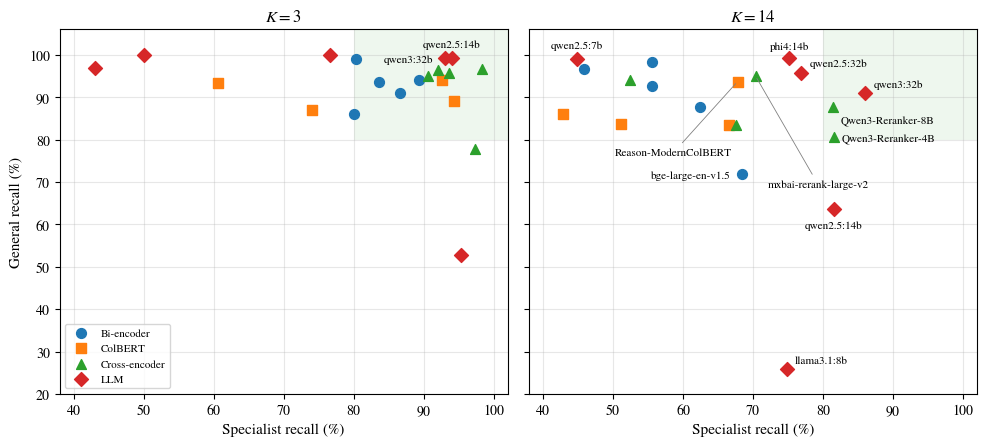

In [22]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

plt.rcParams.update({"font.family": "STIXGeneral", "mathtext.fontset": "stix", "pdf.fonttype": 42,
                     "font.size": 11, "axes.titlesize": 12, "axes.labelsize": 11,
                     "xtick.labelsize": 10, "ytick.labelsize": 10, "legend.fontsize": 10})

style = {"bi-encoder": ("o", "tab:blue", "Bi-encoder"),
         "colbert": ("s", "tab:orange", "ColBERT"),
         "cross-encoder": ("^", "tab:green", "Cross-encoder"),
         "llm": ("D", "tab:red", "LLM")}

labels = {
    3:  {"qwen3:32b": (-8, -3),
         "qwen2.5:14b": (0, 8),},
   14: {"qwen3:32b": (6, 4),
         "Qwen3-Reranker-8B": (6, -12),
         "Qwen3-Reranker-4B": (6, -3),
         "qwen2.5:32b": (6, 5),
         "phi4:14b": (0, 6),
         "Reason-ModernColBERT": (-46, -53),        
         "mxbai-rerank-large-v2": (45, -80),        
         "bge-large-en-v1.5": (-8, -3),
         "qwen2.5:14b": (0, -14),
         "qwen2.5:7b": (0, 8),                      
         "llama3.1:8b": (6, 4)}, 
}

fig, axes = plt.subplots(1, 2, figsize=(10, 4.6), sharex=True, sharey=True)
for ax, k in zip(axes, [3, 14]):
    spec, gen = both[(f"K={k}", "Spec.")], both[(f"K={k}", "Gen.")]

    ax.add_patch(Rectangle((80, 80), 30, 30, color="tab:green", alpha=0.08, lw=0, zorder=0))

    for fam, (marker, color, name) in style.items():
        ax.scatter(spec.loc[fam], gen.loc[fam], marker=marker, color=color,
                   s=50, label=name, zorder=3)

    for fam, router in both.index:
        short = router.split("/")[-1]
        if short in labels[k]:
            dx, dy = labels[k][short]
            far = abs(dx) > 20 or abs(dy) > 20     # far label: centred, with a thin line
            ha = "center" if far or dx == 0 else "right" if dx < 0 else "left"
            ax.annotate(short, (spec[(fam, router)], gen[(fam, router)]),
                        xytext=(dx, dy), textcoords="offset points", ha=ha, fontsize=8,
                        arrowprops=dict(arrowstyle="-", lw=0.6, color="gray") if far else None)

    ax.set_title(f"$K={k}$")
    ax.set_xlabel("Specialist recall (%)")
    ax.set_xlim(38, 102)
    ax.set_ylim(20, 106)
    ax.grid(alpha=0.3)

axes[0].set_ylabel("General recall (%)")
axes[0].legend(loc="lower left", fontsize=8)
plt.tight_layout()
plt.savefig("recall_scatter.pdf")
plt.show()